# Population form: Penmanshiel

Gaussian-process "population forms" for the whole farm, after Bull et al., *Foundations of population-based SHM, Part I: Homogeneous populations and forms* (MSSP 148, 2021), with moving-window novelty and an interactive explorer.

This notebook builds on `analysis_penmanshiel.ipynb`. It reads that notebook's saved output, `data/Penmanshiel/analysis/residuals.parquet`, which holds the temperature residuals, every event flag, the healthy mask and the time split. Nothing from Steps 1–6 is recomputed, so it starts in well under a minute. Run the analysis notebook once first, and again whenever you change its flags, split or normal-behaviour model settings.

In [1]:
import time
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import penmanshiel as pm
from detectors import PCAMonitor

pd.set_option("display.width", 200)

In [2]:
# ------------------------------------------------------------------ settings (must match analysis_penmanshiel.ipynb)

# Flags that make a sample non-healthy (used here to define normal operation for the forms).
HEALTHY_EXCLUDE = ["stop", "warning", "power_reduced", "curtailment", "communication", "forced_outage",
                   "maintenance", "derate", "requested_shutdown", "technical_standby", "electrical_spec",
                   "post_event", "commissioning", "not_running", "derate_setpoint", "missing", "out_of_range"]

# Temperature targets of the normal-behaviour models, and the signals of the raw PCA (analysis Step 3).
TARGETS = ["front_bearing_temperature", "rear_bearing_temperature", "gear_oil_temperature",
           "gear_oil_inlet_temperature", "generator_bearing_front_temperature",
           "generator_bearing_rear_temperature", "stator_temperature_1", "rotor_bearing_temp"]
RAW_SIGNALS = ["wind_speed", "power", "rotor_speed", "blade_angle_pitch_position_a",
               "nacelle_ambient_temperature", "nacelle_temperature", *TARGETS]

VAR_EXPLAINED = 0.90                     # components kept
PERCENTILE = 99.0                        # SPE / T2 threshold on reference data

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#e6e5e0", "#b5b4ad"
LBL = pm.SIGNAL_LABELS | {"power_1h": "Active power, 1 h mean"}

RESIDUALS = pm.DATA_DIR / "analysis" / "residuals.parquet"

def style_ax(ax, grid_axis="both"):
    if grid_axis:
        ax.grid(True, axis=grid_axis, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.title.set_color(INK)

## Data

In [3]:
t0 = time.time()
if not RESIDUALS.exists():
    raise FileNotFoundError(f"{RESIDUALS} not found: run analysis_penmanshiel.ipynb first")
turbines = pm.load_turbines()
TURBINES = turbines["turbine_id"].tolist()
TL = {t: f"T{t:02d}" for t in TURBINES}
scada = pm.load_scada(TURBINES, list(dict.fromkeys([*RAW_SIGNALS, "generator_rpm"])))

saved = pd.read_parquet(RESIDUALS)
if not (np.array_equal(saved["turbine_id"].to_numpy(), scada["turbine_id"].to_numpy())
        and np.array_equal(saved["time_stamp"].to_numpy(), scada["time_stamp"].to_numpy())):
    raise ValueError("residuals.parquet doesn't line up with the SCADA files: re-run analysis_penmanshiel.ipynb")
resid = saved[TARGETS].reset_index(drop=True)
flags = saved[[c for c in saved.columns if saved[c].dtype == bool and c != "healthy"]].reset_index(drop=True)
healthy = saved["healthy"].to_numpy()
period = saved["period"].astype(str).to_numpy()
del saved
# Time split as used by the analysis notebook (end exclusive).
SPLIT = {p: (scada["time_stamp"][period == p].min().normalize(),
             scada["time_stamp"][period == p].max().normalize() + pd.Timedelta("1D"))
         for p in ["reference", "training", "test"] if (period == p).any()}
tid = scada["turbine_id"].to_numpy()
print(f"{len(scada):,} rows, {flags.shape[1]} flags, loaded in {time.time() - t0:.0f} s")
print({p: f"{a:%Y-%m-%d} to {b:%Y-%m-%d}" for p, (a, b) in SPLIT.items()})

5,495,456 rows, 18 flags, loaded in 4 s
{'reference': '2018-06-01 to 2019-06-01', 'training': '2019-06-01 to 2020-06-01', 'test': '2020-06-01 to 2024-01-01'}


In [4]:
# PCA on healthy reference data, as in analysis Step 3; scores feed the "PC / wind speed" state curves.
ref_h = healthy & (period == "reference")
raw_ok = scada[RAW_SIGNALS].notna().all(axis=1).to_numpy()
res_ok = resid.notna().all(axis=1).to_numpy()
pca_raw = PCAMonitor(var_explained=VAR_EXPLAINED, percentile=PERCENTILE).fit(scada.loc[ref_h & raw_ok, RAW_SIGNALS])
pca_res = PCAMonitor(var_explained=VAR_EXPLAINED, percentile=PERCENTILE).fit(resid[ref_h & res_ok])
scores_raw = np.full((len(scada), pca_raw.k_), np.nan, dtype="float32")
scores_raw[raw_ok] = pca_raw.scores(scada.loc[raw_ok, RAW_SIGNALS])
scores_res = np.full((len(scada), pca_res.k_), np.nan, dtype="float32")
scores_res[res_ok] = pca_res.scores(resid[res_ok])
for name, mon, cols in [("raw", pca_raw, RAW_SIGNALS), ("residual", pca_res, TARGETS)]:
    for j in range(mon.k_):
        top = np.argsort(-np.abs(mon.components_[j]))[:3]
        print(f"{name} PC{j + 1} ({mon.full_pca_.explained_variance_ratio_[j]:.0%}): "
              + ", ".join(f"{'+' if mon.components_[j, i] > 0 else '−'} {LBL[cols[i]]}" for i in top))

raw PC1 (39%): + Active power, + Wind speed, + Rotor speed
raw PC2 (25%): + Main (rotor) bearing, + Generator bearing, non-drive end, + Ambient temperature
raw PC3 (15%): + Gearbox oil (sump), − Blade pitch angle, + Gearbox bearing 2 (axle bearing 2)
raw PC4 (7%): + Blade pitch angle, + Gearbox oil inlet, − Ambient temperature
raw PC5 (5%): + Generator bearing, drive end, − Gearbox oil inlet, − Blade pitch angle
residual PC1 (43%): + Gearbox oil (sump), + Gearbox bearing 2 (axle bearing 2), + Gearbox bearing 1 (axle bearing 1)
residual PC2 (23%): + Generator bearing, drive end, + Generator bearing, non-drive end, + Generator stator winding
residual PC3 (11%): + Main (rotor) bearing, − Gearbox oil inlet, − Generator bearing, drive end
residual PC4 (8%): + Gearbox oil inlet, + Main (rotor) bearing, − Gearbox bearing 2 (axle bearing 2)
residual PC5 (7%): + Generator stator winding, − Generator bearing, drive end, + Gearbox oil inlet


## Method

This step follows Bull et al., *Foundations of population-based SHM, Part I: Homogeneous populations and forms* (MSSP 148, 2021). A wind farm of identical turbines is a **homogeneous population**, so one model, the **form**, can describe normal behaviour for all of them. The form is a Gaussian-process (GP) regression of a curve such as power against wind speed, fitted to normal-condition data. Its mean is the typical curve, and its variance covers the normal spread across turbines. Each turbine is then monitored by how far its data fall from the form.

**Curves.** Choose any *x* and *y* from the operating signals, the component temperatures, the raw and residual PCA scores (analysis Step 3) and the temperature residuals, or start from a preset. The presets are power, rotor speed and pitch angle against wind speed; power and pitch angle against generator speed; each PCA score against wind speed ("state curves"); and PC2 against PC1. PCA scores are uncorrelated on the reference data by construction, but only *linearly*. Raw PC2 against PC1, for example, is clearly curved, because the operating point drives both nonlinearly. A PC-against-PC form describes that joint shape, and flags turbines or periods that move away from it.

**The form.** A GP with a squared-exponential kernel plus white noise, with hyperparameters fitted by maximum marginal likelihood. It is fitted to `GP_N_TRAIN` normal-operation samples from the reference year, sampled evenly across *x* so the sparse high-wind end is represented. Normal operation means no event flag from analysis Step 1, and the turbine is either producing power or the wind is below 4 m/s (idling below cut-in is normal). Tick *hold out* to fit the form on alternate turbines only. That matches the paper, which trains on members S1–S10 and tests on the rest; held-out turbines are hatched in the bar chart.

**Which data the form is fitted on** (the *Form* dropdown):
- **Reference year (fixed):** one form from June 2018 to May 2019, as in the paper. The threshold also comes from that year. Slow fleet-wide change (seasons not covered by that year, firmware, sensor swaps) shows up as novelty, and so do farm-wide events.
- **Previous 12 months (rolling):** a new form for every month, fitted on the other turbines' normal data from the 12 months before it. The scored turbine is always left out of its own form, so a slow fault can't be absorbed into it. This adapts to slow fleet-wide drift but still flags sudden farm-wide events.
- **Same window (population at the time):** a form fitted on the other turbines' normal data in the *same* window, so each turbine is compared with the rest of the farm under the same weather. Farm-wide events largely cancel out; what remains is "this turbine differs from the others now". The time series uses consecutive windows of `W` days; the bar chart and scatter use the exact selected window.
- **Both:** rolling and same-window together. The heatmap shows which form flags each turbine-window. *Both* means this turbine differs from the others. *Rolling only* means the whole farm moved, or the curve changed over the year.

The adaptive forms keep the kernel hyperparameters (length scale, signal and noise ratio) of the reference-year fit, and only re-condition the GP on the new data. That takes milliseconds instead of seconds, so all ~1,000 monthly and up to ~40,000 same-window leave-one-out forms can be computed: about 15 s for rolling, and about 3 s (30-day windows), 10 s (7-day) or 2 min (1-day) for same-window. Results are cached. Each adaptive mode sets its threshold from its own normal-data windows over the whole record, so all modes are compared at the same nominal 4.55% exceedance rate. Charts show novelty ÷ threshold, so 1 is the threshold in every mode.

**Differences from the paper:**
- **Variance:** the GP's own variance plus the binned mean squared residual of all normal reference data. The paper assumes constant noise, but power scatters far more mid-curve than at rated power. With constant noise, normal mid-curve scatter would be flagged and deviations at rated power missed.
- **Novelty:** each sample gets *z* = (measured − form mean) / form SD, capped at ±`GP_Z_CAP`. A window's novelty is the mean *z*² over its samples. This is the paper's Mahalanobis squared distance with a diagonal covariance, divided by the number of samples so that windows of different sizes compare. Data that match the form score about 1.
- **Threshold:** the 95.45th percentile (two-sigma, as in the paper) of the window novelty of normal reference data, from the turbines that fitted the form. It is recalculated for each window length. The paper bootstraps random samples instead, but 10-minute samples are autocorrelated, so random resampling sets the threshold too low. This is the same issue as for CUSUM in analysis Step 5.
- **Moving window:** `W` days, ending on each day.

**Test data:**
- *Exclude logged stops and outages* keeps curtailment, derates and warnings, which are the things a curve should reveal.
- *All data* also includes stops.
- *Normal operation only* shows what is left once every flagged event is removed.

**The plots:**
1. The form, with the selected turbine's window.
2. Every turbine's novelty in the same window.
3. A control chart for the selected turbine, like the paper's Fig. 11.
4. Novelty / threshold for every turbine and day.

The reference-year form takes about 10 s to fit the first time a curve is chosen; after that it is cached.

**Limits:**
- **One GP, not a mixture.** The paper's second case study uses an overlapping mixture of GPs (OMGP), so that operator curtailment counts as a second normal curve. Here, curtailment shows up as outlying.
- **Curves against generator speed are not functions near rated speed.** Pitch and power rise at an almost constant generator speed, so the form's variance is very wide there and these curves are less sensitive.
- ***x* values outside the reference range** are clamped to its edge.
- **Residual PC scores:** the residuals are in-sample in the training year (analysis Step 2), so residual PC curves look unusually tidy there.

### How novelty is calculated

1. **Score each 10-minute sample.** At the sample's *x*, the form gives an expected value $\mu(x)$ and a normal spread $\sigma(x)$. The spread combines the GP's uncertainty about the curve with the scatter of normal data at that *x*. The sample's standardised deviation is

   $$z = \frac{y - \mu(x)}{\sigma(x)}$$

   For example, 900 kW at 9 m/s, where the form expects 1,200 ± 150 kW, gives *z* = −2. The spread varies along the curve, so the same 300 kW gap counts for more at rated power than mid-curve. *x* values outside the form's range are clamped to its edge.
2. **Cap it** at |*z*| = `GP_Z_CAP` (10), so a single glitch can't dominate a window.
3. **Average over the window.** For each turbine and each window of `W` days:

   $$\text{novelty} = \frac{1}{n}\sum_{i=1}^{n} z_i^2$$

   This uses the turbine's *n* samples in the window that pass the *Test data* filter. A window needs at least `GP_MIN_FILL` (10%) of its 10-minute slots, otherwise its novelty is blank. Data that behave like the form score about 1. Squaring makes a few large deviations count more than many small ones, and averaging puts a 1-day and a 90-day window on the same scale. This is the paper's Mahalanobis squared distance with a diagonal covariance, divided by *n*.
4. **Compare with a threshold.** The threshold is the `GP_THRESHOLD_PCT` (95.45th, two-sigma) percentile of the novelty of *normal-operation* windows of the same length. Normal windows score a little above 1, because turbines differ slightly and consecutive samples are correlated. The windows used are:
   - **Fixed form:** reference-year windows of the turbines that trained it.
   - **Rolling and same-window forms:** windows over the whole record.

   A window above the threshold is **OUTLYING**. The bar chart, control chart and heatmap show **novelty ÷ threshold**, so 1 is the threshold in every mode.

Rough guide: about 1 means like the form; 1.5–2 means somewhat off or more scattered than usual; 10 or more means far from the form, for example a curtailed or shifted power curve.

In [5]:
from matplotlib.colors import LogNorm
from scipy.linalg import cho_solve, solve_triangular
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

# ------------------------------------------------------------------ settings
GP_N_TRAIN = 1000            # samples used to fit each GP form, stratified over x (the paper used 2000)
GP_FORM_PERIOD = "reference" # the form and its threshold are learnt from normal operation in this period
GP_Z_CAP = 10.0              # per-sample |z| cap, so a single glitch can't dominate a window
GP_THRESHOLD_PCT = 95.45     # two-sigma threshold, as in the paper
GP_MIN_FILL = 0.10           # a window needs at least this share of its 10-minute slots
GP_HOLDOUT_TRAIN = TURBINES[::2]   # turbines that train the form when "hold out half" is ticked
GP_N_ADAPT = 500             # GP samples per rolling form
GP_N_WIN = 120               # GP samples per same-window form (there are thousands of these)
GP_ROLL_MONTHS = 12          # rolling form: fitted on this many months before each month
GP_MIN_FORM = 300            # normal samples needed to fit an adaptive form

# Variables that can go on either axis: signals, component temperatures, PCA scores and temperature residuals.
GP_VARS = {LBL[c]: c for c in ["wind_speed", "power", "rotor_speed", "generator_rpm", "blade_angle_pitch_position_a",
                               "nacelle_ambient_temperature", "nacelle_temperature", *TARGETS]}
GP_VARS |= {f"Raw PC{j + 1}": ("raw", j) for j in range(pca_raw.k_)}
GP_VARS |= {f"Residual PC{j + 1}": ("res", j) for j in range(pca_res.k_)}
GP_VARS |= {f"Residual: {LBL[c]}": ("resid", c) for c in TARGETS}
# Presets: (x, y). Any other pair can be chosen in the widget.
GP_PRESETS = {
    "Power / wind speed": ("Wind speed", "Active power"),
    "Rotor speed / wind speed": ("Wind speed", "Rotor speed"),
    "Pitch angle / wind speed": ("Wind speed", "Blade pitch angle"),
    "Power / generator speed": ("Generator speed", "Active power"),
    "Pitch angle / generator speed": ("Generator speed", "Blade pitch angle"),
    "Raw PC2 / Raw PC1": ("Raw PC1", "Raw PC2"),
    "Residual PC2 / Residual PC1": ("Residual PC1", "Residual PC2"),
}
GP_PRESETS |= {f"Raw PC{j + 1} / wind speed": ("Wind speed", f"Raw PC{j + 1}") for j in range(pca_raw.k_)}
GP_PRESETS |= {f"Residual PC{j + 1} / wind speed": ("Wind speed", f"Residual PC{j + 1}") for j in range(pca_res.k_)}
GP_CURVES = {}  # curve name -> (x spec, y spec); filled by gp_curve()


def gp_curve(x_label, y_label):
    """Register the curve y(x) for two GP_VARS labels and return its name (used as the cache key)."""
    name = f"{y_label} / {x_label}"
    GP_CURVES[name] = (GP_VARS[x_label], GP_VARS[y_label])
    return name


for _x, _y in GP_PRESETS.values():
    gp_curve(_x, _y)
GP_UNITS = {"wind_speed": "m/s", "power": "kW", "rotor_speed": "rpm", "generator_rpm": "rpm",
            "blade_angle_pitch_position_a": "°"}

# Normal operation for the form: no event flag, and either producing power or below cut-in wind (idling at
# low wind is normal and belongs in the form; standing still at 10 m/s is not).
_event_flags = [f for f in HEALTHY_EXCLUDE if f not in ("not_running", "missing")]
gp_normal = (~flags[_event_flags].any(axis=1) & (~flags["not_running"] | (scada["wind_speed"] < 4))).to_numpy()
GP_FILTERS = {
    "Exclude logged stops and outages": ~flags[["stop", "forced_outage", "maintenance", "requested_shutdown",
                                                "technical_standby", "communication", "commissioning",
                                                "out_of_range"]].any(axis=1).to_numpy(),
    "Normal operation only": gp_normal,
    "All data": np.ones(len(scada), dtype=bool),
}

_day0 = scada["time_stamp"].min().normalize()
gp_day = ((scada["time_stamp"] - _day0) // pd.Timedelta("1D")).to_numpy()
gp_days = pd.date_range(_day0, periods=gp_day.max() + 1, freq="D")
gp_tpos = {t: i for i, t in enumerate(TURBINES)}
gp_ti = pd.Series(tid).map(gp_tpos).to_numpy()
gp_rows = {t: np.flatnonzero(tid == t) for t in TURBINES}


def gp_label(spec):
    if isinstance(spec, tuple):
        if spec[0] == "resid":
            return f"{LBL[spec[1]]} residual (°C)"
        return f"{'Raw' if spec[0] == 'raw' else 'Residual'} PC{spec[1] + 1} score"
    unit = GP_UNITS.get(spec, "°C" if "temp" in spec else None)
    return f"{LBL[spec]} ({unit})" if unit else LBL[spec]


def gp_values(spec):
    if isinstance(spec, tuple):
        if spec[0] == "resid":
            return resid[spec[1]].to_numpy(float)
        return (scores_raw if spec[0] == "raw" else scores_res)[:, spec[1]].astype(float)
    return scada[spec].to_numpy(float)


def gp_xy(curve):
    x_spec, y_spec = GP_CURVES[curve]
    return gp_values(x_spec), gp_values(y_spec)


def gp_fit_form(curve, train_turbines):
    """GP form of y(x) from normal reference data of `train_turbines`, evaluated on a grid.

    Predictive variance = GP latent variance + the binned mean squared residual of all normal reference
    samples (the curves are heteroscedastic: e.g. power scatters most mid-curve and least at rated).
    """
    x, y = gp_xy(curve)
    tr = (np.isfinite(x) & np.isfinite(y) & gp_normal & (period == GP_FORM_PERIOD)
          & np.isin(tid, train_turbines))
    xt, yt = x[tr], y[tr]
    lo, hi = np.quantile(xt, [0.0005, 0.9995])
    # Stratified sample, so the sparse high-wind end is represented.
    rng = np.random.default_rng(0)
    nb = 25
    b = np.clip(np.digitize(xt, np.linspace(lo, hi, nb + 1)) - 1, 0, nb - 1)
    idx = np.concatenate([rng.choice(np.flatnonzero(b == k), min(GP_N_TRAIN // nb, (b == k).sum()), replace=False)
                          for k in range(nb) if (b == k).any()])
    mx, sx = xt.mean(), xt.std()
    kernel = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(0.5, (0.02, 10.0)) + WhiteKernel(0.05, (1e-5, 1.0))
    gp = GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=1, random_state=0)
    gp.fit(((xt[idx] - mx) / sx)[:, None], yt[idx])
    grid = np.linspace(lo, hi, 400)
    mean, sd = gp.predict(((grid - mx) / sx)[:, None], return_std=True)
    noise = gp.kernel_.k2.noise_level * gp._y_train_std ** 2
    latent_var = np.clip(sd ** 2 - noise, 0, None)
    # Binned mean squared residual over all normal reference samples (x outside the grid is clamped).
    e2 = (yt - np.interp(xt, grid, mean)) ** 2
    nbv = 50
    edges = np.linspace(lo, hi, nbv + 1)
    bi = np.clip(np.digitize(xt, edges) - 1, 0, nbv - 1)
    cnt, s2 = np.bincount(bi, minlength=nbv), np.bincount(bi, e2, minlength=nbv)
    ok = cnt >= 30
    noise_var = np.interp(grid, ((edges[:-1] + edges[1:]) / 2)[ok], s2[ok] / cnt[ok])
    floor = (0.01 * np.subtract(*np.quantile(yt, [0.99, 0.01]))) ** 2
    return dict(grid=grid, mean=mean, var=np.maximum(latent_var + noise_var, floor),
                xs=xt[idx], ys=yt[idx], train=list(train_turbines), kernel=gp.kernel_, mx=mx, sx=sx)


def gp_z(form, x, y):
    """Standardised deviation from the form (x clamped to the grid)."""
    return (y - np.interp(x, form["grid"], form["mean"])) / np.sqrt(np.interp(x, form["grid"], form["var"]))


def gp_daily(z2, mask):
    """(sum of z^2, count) per day x turbine."""
    n = len(gp_days) * len(TURBINES)
    key = gp_day[mask] * len(TURBINES) + gp_ti[mask]
    shape = (len(gp_days), len(TURBINES))
    return np.bincount(key, z2[mask], n).reshape(shape), np.bincount(key, minlength=n).reshape(shape).astype(float)


def gp_window_scores(S, C, W):
    """Novelty of the W-day window ending on each day: mean capped z^2 (about 1 for data like the form)."""
    cs = np.vstack([np.zeros((1, S.shape[1])), np.cumsum(S, 0)])
    cc = np.vstack([np.zeros((1, C.shape[1])), np.cumsum(C, 0)])
    out = np.full(S.shape, np.nan)
    if W > len(S):
        return out
    sw, cw = cs[W:] - cs[:-W], cc[W:] - cc[:-W]
    need = max(6, GP_MIN_FILL * W * 144)
    out[W - 1:] = np.where(cw >= need, sw / np.maximum(cw, 1), np.nan)
    return out


def gp_threshold(entry, W):
    """GP_THRESHOLD_PCT percentile of the window novelty of normal data from the form's own turbines and period."""
    sc = gp_window_scores(*entry["daily"]["_normal"], W)
    r0, r1 = (gp_days.searchsorted(pd.Timestamp(s)) for s in SPLIT[GP_FORM_PERIOD])
    v = sc[r0 + W - 1:r1][:, [gp_tpos[t] for t in entry["form"]["train"]]]
    return np.nanpercentile(v, GP_THRESHOLD_PCT) if np.isfinite(v).any() else np.nan


_gp_cache = {}


def gp_entry(curve, holdout):
    key = (curve, holdout)
    if key not in _gp_cache:
        form = gp_fit_form(curve, GP_HOLDOUT_TRAIN if holdout else TURBINES)
        x, y = gp_xy(curve)
        valid = np.isfinite(x) & np.isfinite(y)
        z2 = np.minimum(np.nan_to_num(gp_z(form, x, y)) ** 2, GP_Z_CAP ** 2)
        daily = {name: gp_daily(z2, valid & m) for name, m in GP_FILTERS.items()}
        daily["_normal"] = gp_daily(z2, valid & gp_normal)
        _gp_cache[key] = dict(form=form, daily=daily)
    return _gp_cache[key]


# ------------------------------------------------------------------ adaptive forms (rolling and same-window)
# These keep the kernel hyperparameters of the reference-year fit and re-condition the GP on new data, which
# takes milliseconds instead of seconds. The scored turbine is always left out of its own form. Each turbine's
# data in a period is summarised by per-bin sums (on a fine x grid) plus a stratified sample, so the 14
# leave-one-out forms of a period are built from the same summaries.

GP_FORM_MODES = {
    "Reference year (fixed)": ["fixed"],
    f"Previous {GP_ROLL_MONTHS} months (rolling)": ["rolling"],
    "Same window (population at the time)": ["samewin"],
    "Both: rolling and same window": ["rolling", "samewin"],
}
_N_FINE, _PER_COARSE = 200, 5
_gp_split_cache, _gp_roll_cache, _gp_win_cache = {}, {}, {}


def gp_split(curve):
    """Per-turbine arrays for a curve (valid samples only, time-sorted) and the fine x bins."""
    if curve not in _gp_split_cache:
        _gp_split_cache.clear()
        x, y = gp_xy(curve)
        valid = np.isfinite(x) & np.isfinite(y)
        masks = GP_FILTERS | {"_normal": gp_normal}
        per = {}
        for t in TURBINES:
            r = gp_rows[t][valid[gp_rows[t]]]
            per[t] = dict(x=x[r], y=y[r], day=gp_day[r], **{k: m[r] for k, m in masks.items()})
        lo, hi = np.quantile(x[valid], [0.0005, 0.9995])
        edges = np.linspace(lo, hi, _N_FINE + 1)
        _gp_split_cache[curve] = dict(per=per, edges=edges, centres=(edges[:-1] + edges[1:]) / 2)
    return _gp_split_cache[curve]


def gp_hyper(curve, holdout):
    f = gp_entry(curve, holdout)["form"]
    k = f["kernel"]
    return dict(amp=k.k1.k1.constant_value, ls=k.k1.k2.length_scale, noise=k.k2.noise_level, mx=f["mx"], sx=f["sx"])


def _day_slice(d, a, b):
    """Rows of a turbine's data with day in [a, b)."""
    return slice(*np.searchsorted(d["day"], [a, b]))


def _pool(d, sl, edges, m, rng):
    """Per-fine-bin sums and a stratified sample of m normal samples of one turbine in one period."""
    nm = d["_normal"][sl]
    x, y = d["x"][sl][nm].astype(float), d["y"][sl][nm].astype(float)
    fb = np.clip(np.searchsorted(edges, x, "right") - 1, 0, _N_FINE - 1)
    st = dict(n=np.bincount(fb, minlength=_N_FINE).astype(float), sx=np.bincount(fb, x, _N_FINE),
              sy=np.bincount(fb, y, _N_FINE), syy=np.bincount(fb, y * y, _N_FINE))
    if len(x) > m:  # weighted sampling without replacement, weight 1 / (coarse-bin count)
        cb = fb // _PER_COARSE
        key = np.log(rng.random(len(x))) * np.bincount(cb, minlength=_N_FINE // _PER_COARSE)[cb]
        idx = np.argpartition(-key, m)[:m]
        x, y = x[idx], y[idx]
    st["xs"], st["ys"] = x, y
    return st


def _gp_cond(xs, ys, grid, h):
    """GP posterior mean and latent variance on `grid`, with fixed hyperparameters (y normalised as in sklearn)."""
    xn, gn = (xs - h["mx"]) / h["sx"], (grid - h["mx"]) / h["sx"]
    ym, ysd = ys.mean(), ys.std() or 1.0
    K = h["amp"] * np.exp(-0.5 * ((xn[:, None] - xn[None]) / h["ls"]) ** 2) + h["noise"] * np.eye(len(xn))
    L = np.linalg.cholesky(K)
    Ks = h["amp"] * np.exp(-0.5 * ((gn[:, None] - xn[None]) / h["ls"]) ** 2)
    mean = ym + ysd * (Ks @ cho_solve((L, True), (ys - ym) / ysd))
    v = solve_triangular(L, Ks.T, lower=True)
    return mean, ysd ** 2 * np.clip(h["amp"] - (v ** 2).sum(0), 0, None)


def _form_from_pools(pools, centres, h, n_gp=GP_N_ADAPT):
    if not pools:
        return None
    tot = {k: sum(p[k] for p in pools) for k in ("n", "sx", "sy", "syy")}
    n = tot["n"]
    if n.sum() < GP_MIN_FORM:
        return None
    occupied = np.flatnonzero(n >= 3)
    if len(occupied) < 2:
        return None
    grid = centres[occupied[0]:occupied[-1] + 1:2]  # every other fine bin is plenty for a smooth curve
    xs, ys = np.concatenate([p["xs"] for p in pools]), np.concatenate([p["ys"] for p in pools])
    if len(xs) > n_gp:
        keep = np.random.default_rng(0).choice(len(xs), n_gp, replace=False)
        xs, ys = xs[keep], ys[keep]
    mean, latent = _gp_cond(xs, ys, grid, h)
    # Mean squared residual per coarse bin, from the fine-bin sums (form mean taken at each fine bin's mean x).
    has = n > 0
    mu = np.interp(np.where(has, tot["sx"] / np.maximum(n, 1), centres), grid, mean)
    sse = np.clip(tot["syy"] - 2 * mu * tot["sy"] + n * mu ** 2, 0, None)
    nc = n.reshape(-1, _PER_COARSE).sum(1)
    ok = nc >= 20
    if not ok.any():
        return None
    xc = tot["sx"].reshape(-1, _PER_COARSE).sum(1)[ok] / nc[ok]
    noise_var = np.interp(grid, xc, sse.reshape(-1, _PER_COARSE).sum(1)[ok] / nc[ok])
    sd_all = np.sqrt(max(tot["syy"].sum() / n.sum() - (tot["sy"].sum() / n.sum()) ** 2, 0))
    return dict(grid=grid, mean=mean, var=np.maximum(latent + noise_var, (0.05 * sd_all) ** 2 + 1e-12),
                xs=xs, ys=ys)


def _score(form, d, sl):
    """Capped z^2 of a turbine's samples in a slice."""
    return np.minimum(np.nan_to_num(gp_z(form, d["x"][sl].astype(float), d["y"][sl].astype(float))) ** 2,
                      GP_Z_CAP ** 2)


def gp_rolling(curve, holdout):
    """Monthly leave-one-out forms, each fitted on the previous GP_ROLL_MONTHS months of the other turbines.

    Returns daily (sum z^2, count) per filter, like the fixed form, plus the forms for plotting.
    """
    key = (curve, holdout)
    if key in _gp_roll_cache:
        return _gp_roll_cache[key]
    sp, h = gp_split(curve), gp_hyper(curve, holdout)
    train = GP_HOLDOUT_TRAIN if holdout else TURBINES
    rng = np.random.default_rng(0)
    m_per = int(np.ceil(GP_N_ADAPT / max(1, len(train) - 1)))
    first = gp_days[min(d["day"][d["_normal"]].min() for d in sp["per"].values() if d["_normal"].any())]
    months = pd.date_range(gp_days[0].to_period("M").to_timestamp(), gp_days[-1], freq="MS")
    keys = list(GP_FILTERS) + ["_normal"]
    S = {k: np.zeros((len(gp_days), len(TURBINES))) for k in keys}
    C = {k: np.zeros((len(gp_days), len(TURBINES))) for k in keys}
    forms = {}
    for mi, m in enumerate(months):
        if m - pd.DateOffset(months=GP_ROLL_MONTHS) < first:
            continue
        d0, d1 = gp_days.searchsorted(m), gp_days.searchsorted(m + pd.offsets.MonthBegin(1))
        a = gp_days.searchsorted(m - pd.DateOffset(months=GP_ROLL_MONTHS))
        pools = {t: _pool(sp["per"][t], _day_slice(sp["per"][t], a, d0), sp["edges"], m_per, rng) for t in train}
        for t in TURBINES:
            form = _form_from_pools([pools[u] for u in train if u != t], sp["centres"], h)
            if form is None:
                continue
            forms[(mi, t)] = form
            d = sp["per"][t]
            sl = _day_slice(d, d0, d1)
            z2, days, ti = _score(form, d, sl), d["day"][sl], gp_tpos[t]
            for k in keys:
                msk = d[k][sl]
                S[k][:, ti] += np.bincount(days[msk], z2[msk], len(gp_days))
                C[k][:, ti] += np.bincount(days[msk], minlength=len(gp_days))
    _gp_roll_cache[key] = dict(daily={k: (S[k], C[k]) for k in keys}, forms=forms, months=months, train=list(train))
    return _gp_roll_cache[key]


def gp_samewin_window(curve, holdout, a, b):
    """Leave-one-out forms from the other turbines' normal data in days [a, b], and each turbine's novelty."""
    sp, h = gp_split(curve), gp_hyper(curve, holdout)
    train = GP_HOLDOUT_TRAIN if holdout else TURBINES
    rng = np.random.default_rng(a)
    m_per = int(np.ceil(GP_N_WIN / max(1, len(train) - 1)))
    need = max(6, GP_MIN_FILL * (b - a + 1) * 144)
    pools = {t: _pool(sp["per"][t], _day_slice(sp["per"][t], a, b + 1), sp["edges"], m_per, rng) for t in train}
    out = {}
    for t in TURBINES:
        d = sp["per"][t]
        sl = _day_slice(d, a, b + 1)
        if sl.stop - sl.start < need:
            continue
        form = _form_from_pools([pools[u] for u in train if u != t], sp["centres"], h, GP_N_WIN)
        if form is None:
            continue
        z2 = _score(form, d, sl)
        nov = {}
        for k in list(GP_FILTERS) + ["_normal"]:
            msk = d[k][sl]
            nov[k] = z2[msk].mean() if msk.sum() >= need else np.nan
        out[t] = dict(form=form, novelty=nov)
    return out


def gp_samewin(curve, holdout, W):
    """Same-window novelty for consecutive W-day windows (aligned to the last day), spread over each window's days."""
    key = (curve, holdout, W)
    if key in _gp_win_cache:
        return _gp_win_cache[key]
    train = GP_HOLDOUT_TRAIN if holdout else TURBINES
    keys = list(GP_FILTERS) + ["_normal"]
    arr = {k: np.full((len(gp_days), len(TURBINES)), np.nan) for k in keys}
    normal_scores = []
    for e in range(len(gp_days) - 1, W - 2, -W):
        res = gp_samewin_window(curve, holdout, e - W + 1, e)
        for t, r in res.items():
            for k in keys:
                arr[k][e - W + 1:e + 1, gp_tpos[t]] = r["novelty"][k]
            if t in train:
                normal_scores.append(r["novelty"]["_normal"])
    v = np.array(normal_scores, dtype=float)
    thr = np.nanpercentile(v, GP_THRESHOLD_PCT) if np.isfinite(v).any() else np.nan
    _gp_win_cache[key] = dict(scores=arr, thr=thr)
    return _gp_win_cache[key]


def gp_mode_scores(mode, curve, holdout, data_filter, W):
    """(novelty per day x turbine for the W-day window ending that day, threshold) for one form mode."""
    if mode == "samewin":
        r = gp_samewin(curve, holdout, W)
        return r["scores"][data_filter], r["thr"]
    entry = gp_entry(curve, holdout) if mode == "fixed" else gp_rolling(curve, holdout)
    scores = gp_window_scores(*entry["daily"][data_filter], W)
    if mode == "fixed":
        return scores, gp_threshold(entry, W)
    normal = gp_window_scores(*entry["daily"]["_normal"], W)[:, [gp_tpos[t] for t in entry["train"]]]
    return scores, (np.nanpercentile(normal, GP_THRESHOLD_PCT) if np.isfinite(normal).any() else np.nan)


def gp_pending(curve, holdout, modes, W):
    """Message describing slow work that a render will trigger, or None."""
    msgs = []
    if (curve, holdout) not in _gp_cache:
        msgs.append("reference-year GP fit (about 10 s)")
    if "rolling" in modes and (curve, holdout) not in _gp_roll_cache:
        msgs.append("monthly rolling forms (about 30-60 s)")
    if "samewin" in modes and (curve, holdout, W) not in _gp_win_cache:
        msgs.append(f"same-window forms for {len(gp_days) // W} windows (roughly {max(2, round(len(gp_days) / W * 0.04))} s)")
    return ", ".join(msgs) or None


In [6]:
import textwrap
import warnings

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

GP_MODE_STYLE = {  # colour and short name per form mode
    "fixed": (PALETTE[0], "reference-year form"),
    "rolling": (PALETTE[0], f"rolling {GP_ROLL_MONTHS}-month form"),
    "samewin": (PALETTE[2], "same-window form"),
}


def plain_log_ticks(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}" if f"{v:.1g}"[0] in "25" else ""))


def gp_selected(mode, curve, holdout, data_filter, turbine, W, end_i, scores):
    """(form for the turbine, novelty of every turbine) for the selected window, computed exactly."""
    if mode == "samewin":
        res = gp_samewin_window(curve, holdout, max(0, end_i - W + 1), end_i)
        nov = np.array([res[t]["novelty"][data_filter] if t in res else np.nan for t in TURBINES])
        return (res[turbine]["form"] if turbine in res else None), nov
    if mode == "fixed":
        return gp_entry(curve, holdout)["form"], scores[end_i]
    roll = gp_rolling(curve, holdout)
    mi = roll["months"].searchsorted(gp_days[end_i], side="right") - 1
    return roll["forms"].get((mi, turbine)), scores[end_i]


def gp_figure(curve, data_filter, turbine, holdout, W, end_i, form_mode="Reference year (fixed)"):
    modes = GP_FORM_MODES[form_mode]
    res = {}
    for m in modes:
        scores, thr = gp_mode_scores(m, curve, holdout, data_filter, W)
        form, nov = gp_selected(m, curve, holdout, data_filter, turbine, W, end_i, scores)
        with np.errstate(all="ignore"):
            res[m] = dict(ratio=scores / thr, thr=thr, form=form, sel=nov / thr, nov=nov)
    t_i = gp_tpos[turbine]
    start_i = max(0, end_i - W + 1)
    d0, d1 = gp_days[start_i], gp_days[end_i]
    x_col, y_spec = GP_CURVES[curve]
    both = len(modes) == 2

    fig = plt.figure(figsize=(13, 11))
    gs = fig.add_gridspec(3, 3, height_ratios=[1.35, 0.8, 1.0], hspace=0.42, wspace=0.28)
    ax_sc, ax_bar = fig.add_subplot(gs[0, :2]), fig.add_subplot(gs[0, 2])
    ax_cc = fig.add_subplot(gs[1, :])
    ax_hm = fig.add_subplot(gs[2, :], sharex=ax_cc)

    # --- the form(s) and the selected turbine's window
    d = gp_split(curve)["per"][turbine]
    sl = slice(*np.searchsorted(d["day"], [start_i, end_i + 1]))
    msk = d[data_filter][sl]
    xw, yw = d["x"][sl][msk].astype(float), d["y"][sl][msk].astype(float)
    outside = []
    for k, m in enumerate(modes):
        f = res[m]["form"]
        if f is None:
            continue
        color, name = GP_MODE_STYLE[m]
        g, mu, sd = f["grid"], f["mean"], np.sqrt(f["var"])
        if k == 0:
            ax_sc.scatter(f["xs"], f["ys"], s=3, color="#c9c8c2", lw=0, zorder=1,
                          label="form training sample" + (" (other turbines)" if m != "fixed" else ""))
            ax_sc.fill_between(g, mu - 3 * sd, mu + 3 * sd, color="#cde2fb", alpha=0.7, lw=0, zorder=0,
                               label=f"{name} ±3σ")
            ax_sc.plot(g, mu, color=INK, lw=1.5, zorder=3, label=f"{name} mean")
        else:
            ax_sc.plot(g, mu, color=color, lw=1.5, ls="--", zorder=3, label=f"{name} mean")
            for s_ in (-3, 3):
                ax_sc.plot(g, mu + s_ * sd, color=color, lw=0.8, ls=":", zorder=3,
                           label=f"{name} ±3σ" if s_ == 3 else None)
        outside.append(np.abs(gp_z(f, xw, yw)) > 3)
    if outside:
        n_out = np.sum(outside, axis=0)
        groups = [(n_out == 0, PALETTE[0], f"{TL[turbine]} in window")]
        groups += ([(n_out == 1, PALETTE[3], "outside one form's ±3σ"), (n_out == 2, PALETTE[1], "outside both")]
                   if len(outside) == 2 else [(n_out == 1, PALETTE[1], "outside ±3σ")])
        for sel, color, label in groups:
            ax_sc.scatter(xw[sel], yw[sel], s=9, color=color, lw=0, label=label, zorder=4)
    else:
        ax_sc.scatter(xw, yw, s=9, color=PALETTE[0], lw=0, label=f"{TL[turbine]} in window", zorder=4)
    ax_sc.set_xlabel(gp_label(x_col), color=MUTED)
    ax_sc.set_ylabel(gp_label(y_spec), color=MUTED)
    parts = []
    for m in modes:
        nv, th = res[m]["nov"][t_i], res[m]["thr"]
        verdict = "no form or data" if not np.isfinite(nv) else ("OUTLYING" if nv > th else "inlying")
        parts.append(f"{GP_MODE_STYLE[m][1]}: novelty {nv:.2f} / threshold {th:.2f} ({verdict})")
    ax_sc.set_title(f"{TL[turbine]}, {d0:%Y-%m-%d} to {d1:%Y-%m-%d}, {len(xw):,} samples\n" + "\n".join(parts),
                    loc="left", fontsize=9.5)
    ax_sc.legend(fontsize=7.5, frameon=False, loc="best", markerscale=2)
    style_ax(ax_sc)

    # --- every turbine in the same window
    held = [t not in (GP_HOLDOUT_TRAIN if holdout else TURBINES) for t in TURBINES]
    xpos = np.arange(len(TURBINES))
    width = 0.38 if both else 0.7
    for k, m in enumerate(modes):
        v = res[m]["sel"]
        off = (k - 0.5) * width if both else 0
        colors = ([GP_MODE_STYLE[m][0]] * len(v) if both
                  else [PALETTE[1] if np.isfinite(a) and a > 1 else PALETTE[0] for a in v])
        bars = ax_bar.bar(xpos + off, np.nan_to_num(v, nan=0), color=colors, width=width,
                          label=GP_MODE_STYLE[m][1] if both else None)
        for b_, h in zip(bars, held):
            if h:
                b_.set_hatch("///")
                b_.set_edgecolor("white")
    ax_bar.axhline(1, color=INK, lw=1, ls="--", label="threshold")
    ax_bar.legend(fontsize=7.5, frameon=False, loc="best")
    ax_bar.set_yscale("log")
    plain_log_ticks(ax_bar)
    ax_bar.set_xticks(xpos, [str(t) for t in TURBINES], fontsize=7.5)
    ax_bar.get_xticklabels()[t_i].set_fontweight("bold")
    ax_bar.set_xlabel("turbine" + (" (hatched: held out of the form)" if any(held) else ""), color=MUTED, fontsize=8)
    ax_bar.set_ylabel("novelty / threshold", color=MUTED)
    ax_bar.set_title("Every turbine, same window", loc="left", fontsize=10)
    style_ax(ax_bar, grid_axis="y")

    # --- control chart for the selected turbine
    dn = mdates.date2num(gp_days)
    if modes == ["fixed"]:
        r0, r1 = (pd.Timestamp(a) for a in SPLIT[GP_FORM_PERIOD])
        ax_cc.axvspan(r0, r1, color="#efeee9", lw=0, zorder=0)
        ax_cc.annotate("form + threshold fitted here", (mdates.date2num(r0), 1), xycoords=("data", "axes fraction"),
                       xytext=(3, -12), textcoords="offset points", fontsize=8, color=MUTED)
    if not both:
        with warnings.catch_warnings():  # days with no data at all give an all-NaN median
            warnings.simplefilter("ignore", RuntimeWarning)
            ax_cc.plot(dn, np.nanmedian(res[modes[0]]["ratio"], axis=1), color=AXIS, lw=0.8, label="farm median")
    for m in modes:
        ax_cc.plot(dn, res[m]["ratio"][:, t_i], color=GP_MODE_STYLE[m][0] if both else PALETTE[0], lw=1,
                   label=f"{TL[turbine]}, {GP_MODE_STYLE[m][1]}" if both else TL[turbine])
    ax_cc.axhline(1, color=INK, lw=1, ls="--", label="threshold")
    ax_cc.axvline(dn[end_i], color=PALETTE[1], lw=1.2)
    ax_cc.set_yscale("log")
    plain_log_ticks(ax_cc)
    ax_cc.set_ylabel(f"novelty / threshold\n{W}-day window", color=MUTED)
    ax_cc.set_title(f"Control chart, {TL[turbine]} (orange line: selected window end)", loc="left", fontsize=10)
    ax_cc.legend(fontsize=8, frameon=False, loc="upper right", ncol=4)
    style_ax(ax_cc)

    # --- population heatmap
    ext = [dn[0] - 0.5, dn[-1] + 0.5, len(TURBINES) - 0.5, -0.5]
    if both:
        r_roll, r_win = res["rolling"]["ratio"].T, res["samewin"]["ratio"].T
        with np.errstate(invalid="ignore"):
            cat = (r_roll > 1).astype(float) + 2 * (r_win > 1)
        cat[~(np.isfinite(r_roll) & np.isfinite(r_win))] = np.nan
        cols = ["white", GP_MODE_STYLE["rolling"][0], GP_MODE_STYLE["samewin"][0], PALETTE[1]]
        cmap = ListedColormap(cols)
        cmap.set_bad("#f1f0ec")
        ax_hm.imshow(cat, aspect="auto", cmap=cmap, vmin=-0.5, vmax=3.5, interpolation="none", extent=ext)
        ax_hm.legend(handles=[Patch(color=c, label=l) for c, l in zip(cols[1:], [
            "rolling only\n(whole farm moved, or\nchange over the year)", "same window only",
            "both (this turbine\ndiffers)"])], fontsize=8, frameon=False, loc="upper left",
            bbox_to_anchor=(1.0, 1.0))
        ax_hm.set_title("Which form flags each turbine-window (grey: no data; black line: selected window end)",
                        loc="left", fontsize=10)
    else:
        cmap = plt.get_cmap("Oranges").copy()
        cmap.set_under("white")
        cmap.set_bad("#f1f0ec")
        im = ax_hm.imshow(res[modes[0]]["ratio"].T, aspect="auto", cmap=cmap, norm=LogNorm(1, 20),
                          interpolation="none", extent=ext)
        cb = fig.colorbar(im, ax=ax_hm, shrink=0.9, pad=0.01, extend="both")
        cb.outline.set_visible(False)
        ax_hm.set_title("Novelty / threshold for every turbine (white: below threshold; grey: no data; "
                        "blue line: selected window end)", loc="left", fontsize=10)
    ax_hm.axvline(dn[end_i], color=PALETTE[0] if not both else INK, lw=1.2)
    ax_hm.set_yticks(range(len(TURBINES)), [TL[t] for t in TURBINES], fontsize=8)
    ax_hm.xaxis.set_major_locator(mdates.YearLocator())
    ax_hm.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    style_ax(ax_hm, grid_axis=None)
    fig.suptitle(textwrap.fill(f"{curve}: GP population form, {form_mode.lower()} ({data_filter.lower()}, "
                               f"{W}-day window)", 115), x=0.01, ha="left", va="top", fontsize=12, y=0.995)
    fig.subplots_adjust(top=0.88, bottom=0.04, left=0.07, right=0.85 if both else 0.97)
    return fig


In [7]:
import ipywidgets as widgets


def set_output(out, *objs, text=None):
    """Replace the contents of Output `out` (assigning `outputs` directly: VS Code doesn't reliably apply
    clear_output() sent from widget callbacks, so plots would pile up)."""
    fmt = get_ipython().display_formatter.format
    outputs = [] if text is None else [{"output_type": "stream", "name": "stdout", "text": text}]
    for obj in objs:
        data, metadata = fmt(obj)
        outputs.append({"output_type": "display_data", "data": data, "metadata": metadata})
    out.outputs = tuple(outputs)


_wide = {"description_width": "110px"}
gp_w = dict(
    preset=widgets.Dropdown(options=list(GP_PRESETS) + ["(custom)"], value="Power / wind speed", description="Preset",
                            style=_wide, layout=widgets.Layout(width="380px")),
    x=widgets.Dropdown(options=list(GP_VARS), value="Wind speed", description="x", style=_wide,
                       layout=widgets.Layout(width="380px")),
    y=widgets.Dropdown(options=list(GP_VARS), value="Active power", description="y", style=_wide,
                       layout=widgets.Layout(width="380px")),
    form_mode=widgets.Dropdown(options=list(GP_FORM_MODES), value="Reference year (fixed)", description="Form",
                               style=_wide, layout=widgets.Layout(width="380px")),
    data_filter=widgets.Dropdown(options=list(GP_FILTERS), description="Test data", style=_wide,
                                 layout=widgets.Layout(width="380px")),
    turbine=widgets.Dropdown(options=[(TL[t], t) for t in TURBINES], value=8, description="Turbine", style=_wide,
                             layout=widgets.Layout(width="220px")),
    holdout=widgets.Checkbox(value=False, description="Fit the form on half the turbines only (others held out)",
                             indent=False, layout=widgets.Layout(width="420px")),
    W=widgets.IntSlider(value=7, min=1, max=90, description="Window (days)", style=_wide, continuous_update=False,
                        layout=widgets.Layout(width="520px")),
    end_i=widgets.SelectionSlider(options=[(f"{d:%Y-%m-%d}", i) for i, d in enumerate(gp_days)],
                                  value=int(gp_days.searchsorted(pd.Timestamp("2022-01-20"))),
                                  description="Window end", style=_wide, continuous_update=False,
                                  layout=widgets.Layout(width="900px")),
)
gp_out = widgets.Output()


_gp_busy = {"preset": False}


def gp_render(_=None):
    if _gp_busy["preset"]:
        return
    args = {k: w.value for k, w in gp_w.items() if k not in ("preset", "x", "y")}
    if gp_w["x"].value == gp_w["y"].value:
        set_output(gp_out, text="Choose different x and y variables.\n")
        return
    args["curve"] = gp_curve(gp_w["x"].value, gp_w["y"].value)
    pending = gp_pending(args["curve"], args["holdout"], GP_FORM_MODES[args["form_mode"]], args["W"])
    if pending:
        set_output(gp_out, text=f"Computing {pending}; cached afterwards...\n")
    try:
        fig = gp_figure(**args)
    except Exception as err:  # show the error in the widget instead of losing it in the log
        set_output(gp_out, text=f"{type(err).__name__}: {err}\n")
        return
    set_output(gp_out, fig)
    plt.close(fig)


def gp_apply_preset(change):
    if change["new"] not in GP_PRESETS:
        return
    _gp_busy["preset"] = True  # set x and y together, then render once
    gp_w["x"].value, gp_w["y"].value = GP_PRESETS[change["new"]]
    _gp_busy["preset"] = False
    gp_render()


def gp_mark_custom(_):
    if not _gp_busy["preset"] and GP_PRESETS.get(gp_w["preset"].value) != (gp_w["x"].value, gp_w["y"].value):
        _gp_busy["preset"] = True
        gp_w["preset"].value = "(custom)"
        _gp_busy["preset"] = False


gp_w["preset"].observe(gp_apply_preset, names="value")
for k in ("x", "y"):
    gp_w[k].observe(gp_mark_custom, names="value")
for k, w in gp_w.items():
    if k != "preset":
        w.observe(gp_render, names="value")
display(widgets.VBox([
    widgets.HBox([gp_w["preset"], gp_w["x"], gp_w["y"]]),
    widgets.HBox([gp_w["form_mode"], gp_w["turbine"]]),
    widgets.HBox([gp_w["data_filter"], gp_w["W"]]),
    gp_w["holdout"],
    gp_w["end_i"],
    gp_out,
]))
gp_render()


## Reading the results

**Power / wind speed** (*exclude logged stops and outages*):
- **T08 has the clearest turbine-level finding.** From December 2020 to March 2021, and again from October 2021 to July 2022, its power curve is shifted about 1 m/s to the right, with the same shape. The status log has no matching stop or derate. A rigid shift like this points to the nacelle anemometer (its calibration or transfer function) or to yaw misalignment, rather than to the rotor or drivetrain. T02 is also outlying for several months in early 2021. Start the widget at T08 with a 30-day window to see it.
- **Farm-wide bands are population-level events.** They are vertical stripes in the heatmap, where every turbine is outlying at once: autumn 2016, January 2018, August 2020 and early December 2020. In December 2020 the whole farm was held at about 220 kW for days, and none of it was logged as curtailment. A population form flags these because the whole population has left the form. The peer residuals of analysis Step 5 cancel them out, by design.
- **Window length** sets a trade-off. With 1–3 days, short events such as single-day limits stand out but the chart is noisy. With 30 days or more, only sustained changes like T08's remain.

**Comparing the forms** (power curve, 7- and 30-day windows):
- **T08 is flagged by both the rolling and the same-window form.** It is a turbine-level change, not a fleet effect.
- **The rolling form flags far less than the fixed one.** About 4–5% of turbine-days exceed the threshold, close to the nominal 4.55%, against 9–15% for the fixed reference-year form. The fixed form ages: the farm's power curve drifts slightly over the years.
- **In December 2020 the rolling form flags every turbine at about 20× its threshold.** The same-window form flags them less (about 7×) but doesn't clear them. A 7-day window there mixes normal days with limited days, so the other turbines' data are bimodal, and a single GP can't describe that. This is the case the paper's mixture of GPs (OMGP) is built for. A window that lies wholly inside the limited period lets the same-window form follow the flat line instead.

The other curves pick up the same events. Pitch and rotor speed against wind speed respond to the T08 shift, because the measured wind speed is the common input. The PC state curves mix several signals, so they respond to temperature-driven changes as well as performance changes.

## Benchmark: is novelty raised in the month before a turbine fault?

This tests each state curve against the turbine faults in the status log, broken down by fault category. The curves are the 5 classic operating curves, raw PC1–PC5 against wind speed, and raw PC2 against PC1.

**Detector (fixed for this test)**
- **Form:** same-window form with a **60-day moving window**. Each day, every turbine's last 60 days are compared with a form fitted on the *other* turbines' normal data from the same 60 days (leave-one-out).
- **Data scored:** *Normal operation only*. Time when the turbine is stopped, idling in wind above 4 m/s, derated, curtailed, under a warning or settling after a stop is excluded, so the novelty comes only from normal running.
- **Alarm:** the window's novelty ÷ threshold is above 1, checked every day. The threshold is the 95.45th percentile of normal-data novelty over consecutive 60-day windows of the whole record, as in the widget.

**Fault events**
- **Which stops:** Stop rows whose service-contract category is in the *Turbine fault* class of `eda_penmanshiel.ipynb`, now defined in `penmanshiel.STOP_GROUPS`. That covers generator and converter, pitch, mechanical, electrical, sensor, temperature, controller and repeated errors, safety chain and safety stops, emergency stops, WEC shutdown and overspeed. Grid, manual, remote, park and environmental stops are not faults here.
- **Merging:** stops on the same turbine that start within `BENCH_MERGE_HOURS` (24 h) of the previous one's end form one event. Its category is that of its longest stop.
- **Scope:** events starting in the test period (Jun 2020 – Dec 2023).

**Scoring**
- **Detected (TP):** an alarm on any day in the **30 days before the event day**. **Missed (FN):** no alarm in that month.
- **Unscored events:** events whose lead-up month has no normal running are left out, and counted in `unscored events`.
- **Negatives, "quiet months":** for each turbine, reference days every 30 days through the test period with no turbine-fault event in the month before or after. Each quiet month's lead-up is checked the same way: FP if it alarms, TN if not.
- **The same quiet months serve every category,** so a curve's FP and TN are identical across categories. Only TP and FN change.

**Caveats**
- **Many events are short automatic trips.** The breakdown by event length separates them from longer outages, which are more likely to have a developing cause.
- **Events on the same turbine aren't independent,** and the p-values aren't corrected for testing many curves × categories. Read single stars with care.
- **Very rare categories** (a handful of events) give unstable rates.

The daily novelty is saved to `data/Penmanshiel/analysis/form_benchmark_samewin60.parquet` (about 8–10 min the first time), then reloaded while the settings match. Event definitions and metrics are calculated from it in seconds, so `BENCH_LEAD_DAYS` and `BENCH_MERGE_HOURS` can be changed without recomputing.

In [8]:
import json
import re

from scipy.stats import mannwhitneyu

# ------------------------------------------------------------------ benchmark settings
BENCH_CURVES = ["Power / wind speed", "Rotor speed / wind speed", "Pitch angle / wind speed",
                "Power / generator speed", "Pitch angle / generator speed",
                *[f"Raw PC{j + 1} / wind speed" for j in range(pca_raw.k_)], "Raw PC2 / Raw PC1"]
BENCH_W = 60                          # days: same-window form fitted on the other turbines' data in this moving window
BENCH_STEP = 1                        # days between novelty checks (1 = a check for the window ending every day)
BENCH_FILTER = "Normal operation only"  # only normal running is scored: stops, derates, warnings, restarts excluded
BENCH_LEAD_DAYS = 30                  # an event counts as detected if any check in this many days before it alarms
BENCH_MERGE_HOURS = 24                # turbine-fault stops this close to the previous one are one event
BENCH_PERIOD = "test"
BENCH_FILE = pm.DATA_DIR / "analysis" / "form_benchmark_samewin60.parquet"
RECOMPUTE = False                     # True: rebuild even if a matching saved result exists

_a, _b = (int(gp_days.searchsorted(pd.Timestamp(s))) for s in SPLIT[BENCH_PERIOD])
bench_checks = np.arange(max(BENCH_W - 1, _a - BENCH_LEAD_DAYS), _b, BENCH_STEP)  # window-end days scored
_settings = json.dumps(dict(curves=[GP_CURVES[gp_curve(*GP_PRESETS[c])] for c in BENCH_CURVES], W=BENCH_W,
                            step=BENCH_STEP, filter=BENCH_FILTER, first=int(bench_checks[0]), last=int(bench_checks[-1]),
                            n_win=GP_N_WIN, pct=GP_THRESHOLD_PCT, zcap=GP_Z_CAP, fill=GP_MIN_FILL), default=str)
_meta = BENCH_FILE.with_suffix(".json")

if not RECOMPUTE and BENCH_FILE.exists() and _meta.exists() and json.loads(_meta.read_text()) == json.loads(_settings):
    bench_nov = pd.read_parquet(BENCH_FILE)
    print(f"Loaded {BENCH_FILE.name}: {len(bench_nov):,} turbine-day checks")
else:
    t_all, rows = time.time(), []
    for curve_name in BENCH_CURVES:
        t0 = time.time()
        curve = gp_curve(*GP_PRESETS[curve_name])
        thr = gp_samewin(curve, False, BENCH_W)["thr"]  # threshold from normal-data novelty, as in the widget
        ratio = np.full((len(bench_checks), len(TURBINES)), np.nan)
        for i, e in enumerate(bench_checks):
            for t, r in gp_samewin_window(curve, False, e - BENCH_W + 1, e).items():
                ratio[i, gp_tpos[t]] = r["novelty"][BENCH_FILTER] / thr
        rows.append(pd.DataFrame({"curve": curve_name, "day": np.repeat(bench_checks, len(TURBINES)),
                                  "turbine": np.tile(TURBINES, len(bench_checks)), "ratio": ratio.ravel(),
                                  "threshold": thr}))
        print(f"{curve_name:32s} {time.time() - t0:5.0f} s", flush=True)
    bench_nov = pd.concat(rows, ignore_index=True)
    bench_nov.to_parquet(BENCH_FILE, index=False)
    _meta.write_text(_settings)
    print(f"Computed in {(time.time() - t_all) / 60:.1f} min; saved {BENCH_FILE.name}")
# novelty / threshold per curve as an array [check, turbine]
bench_ratio = {c: g.pivot(index="day", columns="turbine", values="ratio").reindex(index=bench_checks, columns=TURBINES)
               .to_numpy() for c, g in bench_nov.groupby("curve", sort=False)}
print(f"{len(bench_checks):,} daily checks from {gp_days[bench_checks[0]]:%Y-%m-%d} to {gp_days[bench_checks[-1]]:%Y-%m-%d}; "
      f"share of turbine-days with a novelty value: {np.isfinite(bench_nov['ratio']).mean():.0%}")


Loaded form_benchmark_samewin60.parquet: 206,206 turbine-day checks
1,339 daily checks from 2020-05-02 to 2023-12-31; share of turbine-days with a novelty value: 96%


In [9]:
# Turbine-fault events from the status log: Stop rows whose service-contract category is in the "Turbine fault"
# class (pm.STOP_GROUPS, as in eda_penmanshiel.ipynb), merged per turbine when they follow within BENCH_MERGE_HOURS.
_strip = lambda s: re.sub(r"\s*\(\d+\)\s*$", "", str(s)).strip()
_st = pm.load_status(TURBINES)
_fs = (_st[(_st["status"] == "Stop") & _st["timestamp_end"].notna()
           & _st["service_contract_category"].astype(str).isin(pm.TURBINE_FAULT_CATEGORIES)]
       .sort_values(["turbine_id", "timestamp_start"]))
_gap = pd.Timedelta(hours=BENCH_MERGE_HOURS)
_ev = []
for t, g in _fs.groupby("turbine_id"):
    cur = None
    for r in g.itertuples(index=False):
        if cur is not None and r.timestamp_start <= cur["end"] + _gap:
            cur["end"] = max(cur["end"], r.timestamp_end)
            cur["n_stops"] += 1
            if r.duration > cur["longest"]:  # the event takes the category of its longest stop
                cur.update(longest=r.duration, category=_strip(r.service_contract_category), code=r.code, message=r.message)
        else:
            if cur is not None:
                _ev.append(cur)
            cur = dict(turbine=int(t), start=r.timestamp_start, end=r.timestamp_end, n_stops=1, longest=r.duration,
                       category=_strip(r.service_contract_category), code=r.code, message=r.message)
    _ev.append(cur)
fault_events = pd.DataFrame(_ev)
fault_events["hours"] = (fault_events["end"] - fault_events["start"]) / pd.Timedelta("1h")
fault_events["length"] = pd.cut(fault_events["hours"], [0, 1 / 6, 1, 24, np.inf], right=False,
                                labels=["< 10 min", "10 min – 1 h", "1 h – 1 day", "> 1 day"])
fault_events["day"] = gp_days.searchsorted(fault_events["start"].dt.normalize())
in_test = (fault_events["day"] >= _a) & (fault_events["day"] < _b)
test_events = fault_events[in_test].reset_index(drop=True)
print(f"{len(_fs):,} turbine-fault stops -> {len(fault_events):,} events after merging; {len(test_events):,} start in the "
      f"{BENCH_PERIOD} period ({gp_days[_a]:%Y-%m-%d} to {gp_days[_b - 1]:%Y-%m-%d})")
display(test_events.groupby("category").agg(
    events=("hours", "size"), turbines=("turbine", "nunique"), stops=("n_stops", "sum"),
    median_minutes=("hours", lambda h: 60 * h.median()), over_1h=("hours", lambda h: (h >= 1).mean()),
    total_hours=("hours", "sum")).sort_values("events", ascending=False).round(2))


3,278 turbine-fault stops -> 1,188 events after merging; 586 start in the test period (2020-06-01 to 2023-12-31)


,events,turbines,stops,median_minutes,over_1h,total_hours
category,,,,,,
Safety stop of WEC,151,14,324,29.58,0.43,702.86
Sensor error,122,13,568,39.10,0.48,1376.53
Generator and Converter errors,118,14,400,100.71,0.53,2238.01
Mechanical error,87,14,213,10.95,0.34,722.63
Pitch errors,54,14,147,1103.39,0.80,2079.52
Electrical error,29,10,132,446.43,0.83,1889.82
Safety chain,12,10,65,599.56,0.50,202.26
Repeated error,6,5,10,79.27,0.67,67.88
Controller error of the WP3100,3,3,3,12.88,0.00,0.64


### What the columns mean

The unit is an **event** (positives) or a **quiet month** (negatives), each judged on its lead-up month:

| | Alarm in the month before | No alarm |
|---|---|---|
| **Fault event** | TP (detected) | FN (missed) |
| **Quiet month** | FP (false alarm) | TN |

| Column | Meaning | Chance level |
|---|---|---|
| events | Scored events in the category | — |
| detection rate | TP / (TP + FN): share of events with an alarm in the month before | = false-alarm rate |
| false-alarm rate | FP / (FP + TN): share of quiet months with an alarm. The same for every category of a curve. | — |
| precision | TP / (TP + FP). It depends on how many events a category has compared with the number of quiet months, so only compare it within a category. | — |
| MCC | Correlation between alarm and fault, from −1 to 1 | 0 |
| ROC-AUC | Probability that an event's lead-up month has a higher peak novelty than a random quiet month's. This is threshold-free. | 0.5 |
| p (AUC > 0.5) | One-sided Mann–Whitney test of the AUC against chance, uncorrected | — |
| unscored events | Events with no normal running in their lead-up month | — |

A curve is only useful for a category if its **detection rate is clearly above its false-alarm rate**, which is the same thing as ROC-AUC above 0.5. A high detection rate on its own can just mean the curve alarms often.

In [10]:
def _lead_max(ratio, t_idx, day):
    """Largest novelty / threshold over the checks in the BENCH_LEAD_DAYS before `day` (NaN if none scored)."""
    i0, i1 = np.searchsorted(bench_checks, [day - BENCH_LEAD_DAYS, day])
    v = ratio[i0:i1, t_idx]
    return np.nanmax(v) if np.isfinite(v).any() else np.nan


# Quiet months (negatives): for each turbine, reference days every BENCH_LEAD_DAYS through the test period with
# no turbine-fault event in the month before or after; the lead-up month before each is scored like an event's.
_ref = np.arange(_a + BENCH_LEAD_DAYS, _b, BENCH_LEAD_DAYS)
quiet = []
for t in TURBINES:
    ev_days = fault_events.loc[fault_events["turbine"] == t, "day"].to_numpy()
    for r in _ref:
        if not ((ev_days >= r - BENCH_LEAD_DAYS) & (ev_days < r + BENCH_LEAD_DAYS)).any():
            quiet.append((t, r))
quiet = pd.DataFrame(quiet, columns=["turbine", "day"])

ev_score = pd.DataFrame({c: [_lead_max(bench_ratio[c], gp_tpos[t], d) for t, d in zip(test_events["turbine"], test_events["day"])]
                         for c in BENCH_CURVES})
q_score = pd.DataFrame({c: [_lead_max(bench_ratio[c], gp_tpos[t], d) for t, d in zip(quiet["turbine"], quiet["day"])]
                        for c in BENCH_CURVES})
print(f"{len(quiet):,} quiet turbine-months (negatives); {len(test_events):,} fault events (positives)")


def event_metrics(e, q):
    """Event-level confusion matrix and scores from lead-up-month maxima of events (e) and quiet months (q)."""
    e, q = e[np.isfinite(e)], q[np.isfinite(q)]
    TP, FN, FP, TN = (e > 1).sum(), (e <= 1).sum(), (q > 1).sum(), (q <= 1).sum()
    div = lambda a, b: a / b if b else np.nan
    den = np.sqrt(float((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN)))
    if len(e) and len(q):
        u = mannwhitneyu(e, q, alternative="greater")
        auc, p = u.statistic / (len(e) * len(q)), u.pvalue
    else:
        auc = p = np.nan
    return {"events": len(e), "TP": TP, "FN": FN, "FP": FP, "TN": TN, "detection rate": div(TP, TP + FN),
            "false-alarm rate": div(FP, FP + TN), "precision": div(TP, TP + FP),
            "MCC": div(TP * TN - FP * FN, den), "ROC-AUC": auc, "p (AUC > 0.5)": p}


def breakdown(by):
    """Metrics per curve and per level of `by` (a test_events column), plus all turbine faults together."""
    rows = []
    for c in BENCH_CURVES:
        q = q_score[c].to_numpy()
        rows.append({"curve": c, by: "All turbine faults", **event_metrics(ev_score[c].to_numpy(), q),
                     "unscored events": ev_score[c].isna().sum()})
        for lvl, idx in test_events.groupby(by, observed=True).groups.items():
            rows.append({"curve": c, by: lvl, **event_metrics(ev_score.loc[idx, c].to_numpy(), q),
                         "unscored events": ev_score.loc[idx, c].isna().sum()})
    return pd.DataFrame(rows).set_index(["curve", by])


by_category = breakdown("category")
by_length = breakdown("length")
_fmt = {"detection rate": "{:.0%}", "false-alarm rate": "{:.0%}", "precision": "{:.2f}", "MCC": "{:.2f}",
        "ROC-AUC": "{:.2f}", "p (AUC > 0.5)": "{:.3f}"}
display(by_category.xs("All turbine faults", level="category").sort_values("ROC-AUC", ascending=False)
        .style.format(_fmt).background_gradient(subset=["ROC-AUC", "detection rate"], cmap="Blues"))


131 quiet turbine-months (negatives); 586 fault events (positives)


,events,TP,FN,FP,TN,detection rate,false-alarm rate,precision,MCC,ROC-AUC,p (AUC > 0.5),unscored events
curve,,,,,,,,,,,,
Power / wind speed,564,108,456,7,123,19%,5%,0.94,0.14,0.66,0.000,22
Rotor speed / wind speed,564,170,394,27,103,30%,21%,0.86,0.08,0.59,0.001,22
Raw PC2 / Raw PC1,564,99,465,10,120,18%,8%,0.91,0.11,0.58,0.001,22
Raw PC2 / wind speed,564,92,472,15,115,16%,12%,0.86,0.05,0.54,0.057,22
Pitch angle / generator speed,564,131,433,23,107,23%,18%,0.85,0.05,0.54,0.066,22
Raw PC1 / wind speed,564,100,464,16,114,18%,12%,0.86,0.06,0.53,0.144,22
Pitch angle / wind speed,564,83,481,10,120,15%,8%,0.89,0.08,0.53,0.172,22
Raw PC4 / wind speed,564,100,464,15,115,18%,12%,0.87,0.06,0.52,0.187,22
Raw PC3 / wind speed,564,126,438,20,110,22%,15%,0.86,0.07,0.52,0.285,22


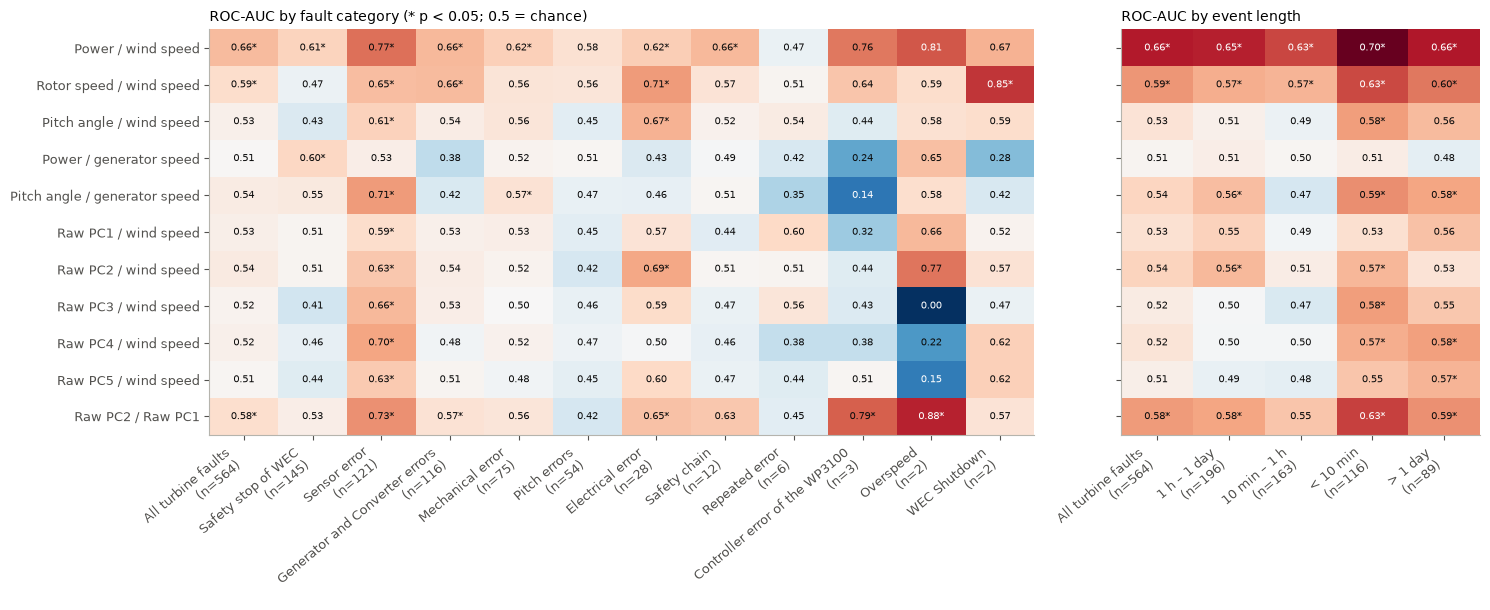

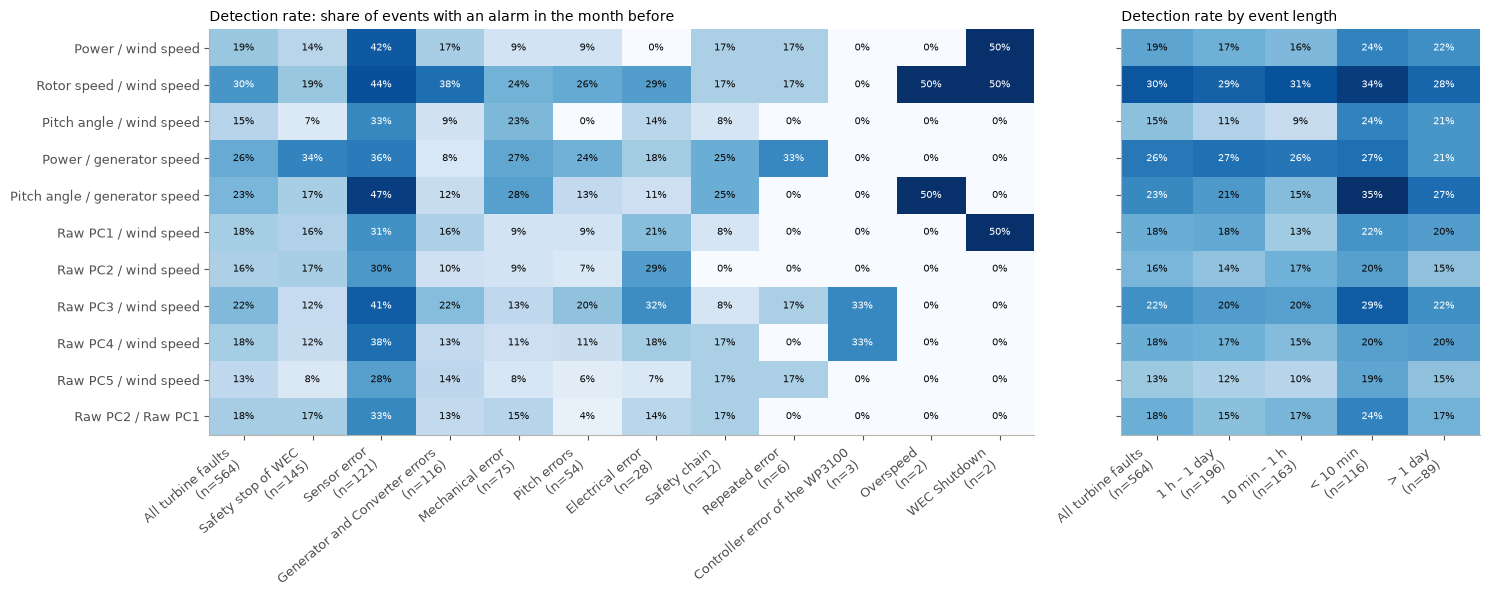

False-alarm rate (share of quiet months with an alarm), by curve: {'Power / wind speed': 0.05, 'Rotor speed / wind speed': 0.21, 'Pitch angle / wind speed': 0.08, 'Power / generator speed': 0.25, 'Pitch angle / generator speed': 0.18, 'Raw PC1 / wind speed': 0.12, 'Raw PC2 / wind speed': 0.12, 'Raw PC3 / wind speed': 0.15, 'Raw PC4 / wind speed': 0.12, 'Raw PC5 / wind speed': 0.11, 'Raw PC2 / Raw PC1': 0.08}


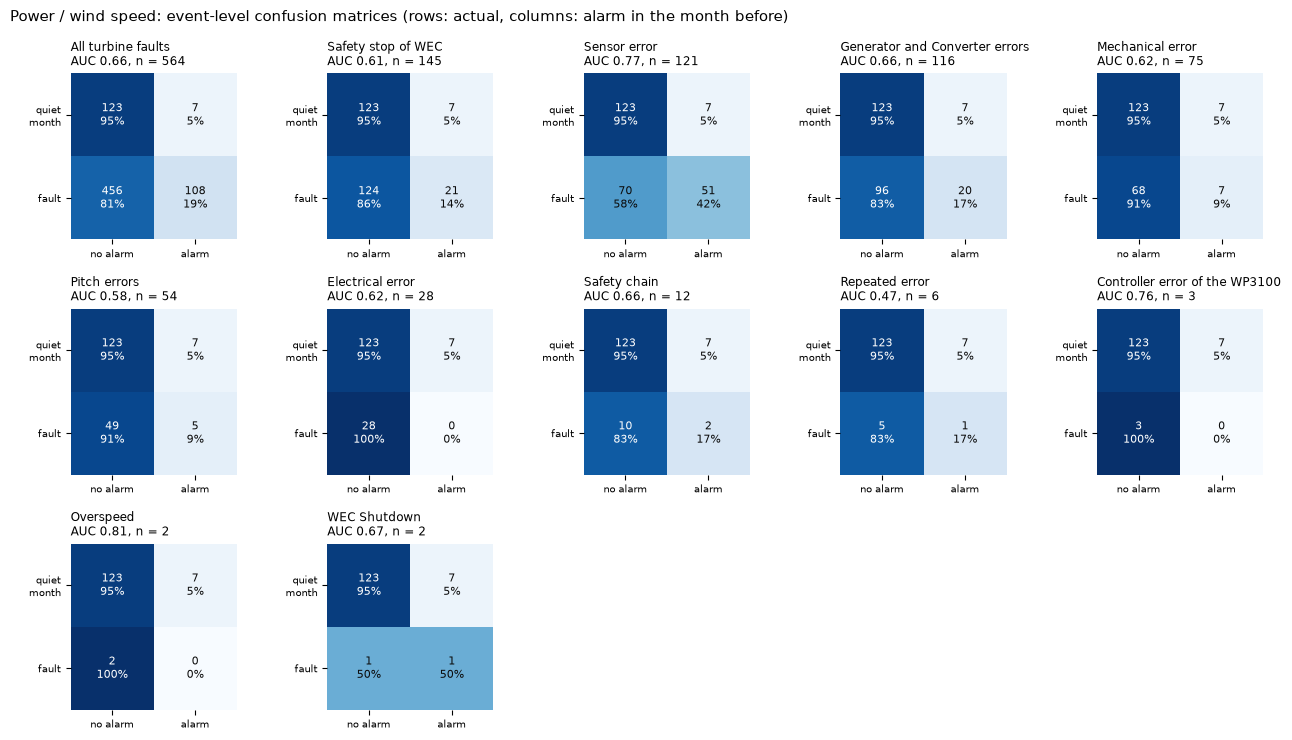

In [11]:
# Heatmaps: curves x fault category and curves x event length. Cell text = ROC-AUC; * = one-sided Mann-Whitney
# p < 0.05 (uncorrected). Column labels give the number of scored events.
def _heat(ax, table, metric, title, cmap, centre=None, fmt="{:.2f}"):
    cats = [c for c in table.index.get_level_values(1).unique()]
    cats = ["All turbine faults"] + sorted([c for c in cats if c != "All turbine faults"],
                                           key=lambda c: -table.xs(c, level=1)["events"].max())
    grid = table[metric].unstack(1).reindex(index=BENCH_CURVES, columns=cats)
    pv = table["p (AUC > 0.5)"].unstack(1).reindex(index=BENCH_CURVES, columns=cats)
    n = table["events"].unstack(1).reindex(index=BENCH_CURVES, columns=cats).max()
    vals = grid.to_numpy(float)
    if centre is None:
        im = ax.imshow(vals, cmap=cmap, vmin=0, vmax=max(0.01, np.nanmax(vals)), aspect="auto")
    else:
        lim = max(0.05, np.nanmax(np.abs(vals - centre)))
        im = ax.imshow(vals, cmap=cmap, vmin=centre - lim, vmax=centre + lim, aspect="auto")
    for a in range(vals.shape[0]):
        for b in range(vals.shape[1]):
            v = vals[a, b]
            if np.isnan(v):
                continue
            star = "*" if metric == "ROC-AUC" and pv.iat[a, b] < 0.05 else ""
            dark = abs(v - (centre if centre is not None else 0)) > 0.6 * (lim if centre is not None else np.nanmax(vals))
            ax.text(b, a, fmt.format(v) + star, ha="center", va="center", fontsize=7.5, color="white" if dark else INK)
    ax.set_xticks(range(len(cats)), [f"{c}\n(n={int(n[c])})" for c in cats], rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(BENCH_CURVES)), BENCH_CURVES, fontsize=8)
    ax.set_title(title, loc="left", fontsize=10)
    style_ax(ax, grid_axis=None)
    return im


fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [2.3, 1]})
_heat(axes[0], by_category, "ROC-AUC", "ROC-AUC by fault category (* p < 0.05; 0.5 = chance)", "RdBu_r", centre=0.5)
_heat(axes[1], by_length, "ROC-AUC", "ROC-AUC by event length", "RdBu_r", centre=0.5)
axes[1].set_yticklabels([])
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [2.3, 1]})
_heat(axes[0], by_category, "detection rate", "Detection rate: share of events with an alarm in the month before",
      "Blues", fmt="{:.0%}")
_heat(axes[1], by_length, "detection rate", "Detection rate by event length", "Blues", fmt="{:.0%}")
axes[1].set_yticklabels([])
fig.tight_layout()
plt.show()
_far = by_category.xs("All turbine faults", level="category")["false-alarm rate"]
print("False-alarm rate (share of quiet months with an alarm), by curve:", _far.round(2).to_dict())


def show_confusion(curve_name, by="category"):
    """Event-level confusion matrix for every fault category (or event length) of one curve."""
    table = by_category if by == "category" else by_length
    t = table.xs(curve_name, level="curve")
    t = t.loc[["All turbine faults"] + [i for i in t.sort_values("events", ascending=False).index if i != "All turbine faults"]]
    ncol = 5
    nrow = int(np.ceil(len(t) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13, 2.5 * nrow))
    for ax, (name, r) in zip(axes.flat, t.iterrows()):
        cm = np.array([[r.TN, r.FP], [r.FN, r.TP]], dtype=float)
        ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                share = cm[a, b] / cm[a].sum() if cm[a].sum() else np.nan
                ax.text(b, a, f"{cm[a, b]:.0f}\n{share:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if share > 0.6 else INK)
        ax.set_xticks([0, 1], ["no alarm", "alarm"], fontsize=7.5)
        ax.set_yticks([0, 1], ["quiet\nmonth", "fault"], fontsize=7.5)
        ax.set_title(f"{name}\nAUC {r['ROC-AUC']:.2f}, n = {int(r.events)}", fontsize=8.5, loc="left")
        for sp in ax.spines.values():
            sp.set_visible(False)
    for ax in list(axes.flat)[len(t):]:
        ax.axis("off")
    fig.suptitle(f"{curve_name}: event-level confusion matrices (rows: actual, columns: alarm in the month before)",
                 x=0.01, ha="left", fontsize=10.5)
    fig.tight_layout()
    plt.show()


best_curve = by_category.xs("All turbine faults", level="category")["ROC-AUC"].idxmax()
show_confusion(best_curve)


In [12]:
# Best state curve for each fault category: highest ROC-AUC, with the runner-up for comparison.
BEST_MIN_EVENTS = 10   # categories with fewer scored events are listed but flagged as too small to judge


def best_curves(table, by):
    rows = []
    for lvl, g in table.groupby(level=by, sort=False):
        g = g.droplevel(by).sort_values("ROC-AUC", ascending=False)
        top, second = g.iloc[0], g.iloc[1]
        n = int(top["events"])
        verdict = ("too few events" if n < BEST_MIN_EVENTS
                   else "significant" if top["p (AUC > 0.5)"] < 0.05 else "not significant")
        rows.append({by: lvl, "events": n, "best curve": g.index[0], "ROC-AUC": top["ROC-AUC"],
                     "p (AUC > 0.5)": top["p (AUC > 0.5)"], "detection rate": top["detection rate"],
                     "false-alarm rate": top["false-alarm rate"], "runner-up": g.index[1],
                     "runner-up AUC": second["ROC-AUC"], "verdict": verdict})
    out = pd.DataFrame(rows).set_index(by)
    first = out.loc[["All turbine faults"]] if "All turbine faults" in out.index else out.iloc[:0]
    return pd.concat([first, out.drop(index="All turbine faults", errors="ignore").sort_values("events", ascending=False)])


def _style_best(df):
    shade = {"significant": "background-color: #cde2fb", "not significant": "", "too few events": "color: #9a9993"}
    return (df.style.format({"ROC-AUC": "{:.2f}", "runner-up AUC": "{:.2f}", "p (AUC > 0.5)": "{:.3f}",
                             "detection rate": "{:.0%}", "false-alarm rate": "{:.0%}"})
            .apply(lambda r: [shade[r["verdict"]]] * len(r), axis=1)
            .set_properties(subset=["best curve"], **{"font-weight": "bold"}))


best_by_category = best_curves(by_category, "category")
print("Best curve per fault category (blue: AUC significantly above 0.5; grey: fewer than "
      f"{BEST_MIN_EVENTS} events, too few to judge)")
display(_style_best(best_by_category))
print("\nBest curve per event length")
display(_style_best(best_curves(by_length, "length")))


Best curve per fault category (blue: AUC significantly above 0.5; grey: fewer than 10 events, too few to judge)


,events,best curve,ROC-AUC,p (AUC > 0.5),detection rate,false-alarm rate,runner-up,runner-up AUC,verdict
category,,,,,,,,,
All turbine faults,564,Power / wind speed,0.66,0.000,19%,5%,Rotor speed / wind speed,0.59,significant
Safety stop of WEC,145,Power / wind speed,0.61,0.001,14%,5%,Power / generator speed,0.60,significant
Sensor error,121,Power / wind speed,0.77,0.000,42%,5%,Raw PC2 / Raw PC1,0.73,significant
Generator and Converter errors,116,Power / wind speed,0.66,0.000,17%,5%,Rotor speed / wind speed,0.66,significant
Mechanical error,75,Power / wind speed,0.62,0.002,9%,5%,Pitch angle / generator speed,0.57,significant
Pitch errors,54,Power / wind speed,0.58,0.051,9%,5%,Rotor speed / wind speed,0.56,not significant
Electrical error,28,Rotor speed / wind speed,0.71,0.000,29%,21%,Raw PC2 / wind speed,0.69,significant
Safety chain,12,Power / wind speed,0.66,0.032,17%,5%,Raw PC2 / Raw PC1,0.63,significant
Repeated error,6,Raw PC1 / wind speed,0.60,0.210,0%,12%,Raw PC3 / wind speed,0.56,too few events



Best curve per event length


,events,best curve,ROC-AUC,p (AUC > 0.5),detection rate,false-alarm rate,runner-up,runner-up AUC,verdict
length,,,,,,,,,
All turbine faults,564,Power / wind speed,0.66,0.000,19%,5%,Rotor speed / wind speed,0.59,significant
1 h – 1 day,196,Power / wind speed,0.65,0.000,17%,5%,Raw PC2 / Raw PC1,0.58,significant
10 min – 1 h,163,Power / wind speed,0.63,0.000,16%,5%,Rotor speed / wind speed,0.57,significant
< 10 min,116,Power / wind speed,0.70,0.000,24%,5%,Raw PC2 / Raw PC1,0.63,significant
> 1 day,89,Power / wind speed,0.66,0.000,22%,5%,Rotor speed / wind speed,0.60,significant


### Reading the benchmark

Detector: 60-day same-window form, *Normal operation only*, alarm in the 30 days before each event. There are 586 turbine-fault events in the test period (564 scored), against 131 quiet turbine-months.

- **The power curve against wind speed is the best curve overall:**
  - ROC-AUC 0.66 (p < 0.001), with a 19% detection rate against a 5% false-alarm rate;
  - better than chance for 6 of the 8 categories with enough events;
  - better than chance for every event length, including trips under 10 minutes.

  Rotor speed against wind speed (0.59) and raw PC2 against PC1 (0.58) follow. The other PC curves, and the curves against generator speed, are close to chance overall.
- **Sensor errors are detected best, and the result makes physical sense.** 97 of the 121 sensor-error events are *Anemometer defect* stops, spread across 13 turbines. A failing anemometer misreads the wind for weeks before it trips, which shifts every curve plotted against wind speed. AUCs:
  - 0.77 for the power curve (42% detected), 0.73 for PC2 against PC1, 0.71 for pitch against generator speed;
  - still 0.74 for the power curve without T08, whose anemometer fault is described in the T08 investigation.
- **Other categories with a signal:**
  - generator and converter errors (power curve 0.66, rotor speed 0.66);
  - electrical errors (rotor speed 0.71, PC2 against wind speed 0.69);
  - safety stops (power curve 0.61) and mechanical errors (power curve 0.62).
- **Pitch errors show almost nothing:** at best 0.58 and not significant, even on the pitch curves. Pitch faults here look sudden: battery and charging-circuit trips, not slow degradation.
- **Event length makes little difference to the power curve:** AUC is 0.63–0.70 in every length class. So whatever shows up in the month before isn't limited to long outages.
- **Absolute performance is modest.** The best detection rate at a 5% false-alarm rate is about 1 event in 5, or 2 in 5 for sensor faults. Useful as a screen for anemometer problems, not as a general fault predictor.

**Limitations**
- **Few negatives.** Turbine faults are frequent (about one event per turbine-month), so only 131 turbine-months are clear of faults for a month either side, and they're unevenly spread: T02 has 2, T11 has 4.
- **Turbine identity and timing are partly mixed together.** Turbines with many faults contribute many events but few quiet months. Comparing each turbine's events only with its own quiet months, the power curve's AUC is above 0.5 for 9 of 13 turbines, and from 0.71 to 0.77 for T06, T08, T10, T13 and T14.
- **Small categories and missing corrections.** Categories with fewer than about 10 events (repeated, controller, overspeed, WEC shutdown) are anecdotal. The stars are uncorrected for multiple testing.